In [1]:
# import modules
import numpy as np
import tensorflow as tf
from tensorflow import keras
import pandas as pd
import seaborn as sns
from pylab import rcParams
import matplotlib.pyplot as plt
from sklearn.model_selection import GroupShuffleSplit
from scipy import stats
from sklearn.preprocessing import OneHotEncoder
from sklearn.model_selection import train_test_split
from tensorflow.keras import optimizers
from datetime import datetime
from kerastuner.tuners import RandomSearch
import tensorflow_addons as tfa
from keras.utils import to_categorical 
from keras.regularizers import l2
from scipy.stats import mode



r_seed = 42

WORKDIR = 'C:/Users/cristiano.nascimento/git/LSTM_giroscopio_acelerometro'
np.random.seed(r_seed)
tf.random.set_seed(r_seed)
data_hora= datetime.now().strftime('%Y-%m-%d_%H-%M-%S')
LOG_DIR = WORKDIR + "/Code/DataPrep/"+data_hora

C:\Users\cristiano.nascimento\AppData\Local\Temp\ipykernel_44100\2084090043.py:15: DeprecationWarning: `import kerastuner` is deprecated, please use `import keras_tuner`.
  from kerastuner.tuners import RandomSearch
c:\Users\cristiano.nascimento\git\LSTM_giroscopio_acelerometro\.venv\lib\site-packages\tensorflow_addons\utils\tfa_eol_msg.py:23: UserWarning: 

TensorFlow Addons (TFA) has ended development and introduction of new features.
TFA has entered a minimal maintenance and release mode until a planned end of life in May 2024.
Please modify downstream libraries to take dependencies from other repositories in our TensorFlow community (e.g. Keras, Keras-CV, and Keras-NLP). 

For more information see: https://github.com/tensorflow/addons/issues/2807 

  warnings.warn(


In [2]:
date = datetime.now()
date = date.strftime("%d/%m/%Y_%H:%M")
arq = datetime.now()
arq = arq.strftime("%d_%m_%Y_%H_%M")

In [3]:
## get dataset
pd.set_option("display.precision", 9)

final_columns =['tBodyAcc-Mean-1',
'tBodyAcc-Mean-2',
'tBodyAcc-Mean-3',
'tBodyAcc-STD-1',
'tBodyAcc-STD-2',
'tBodyAcc-STD-3',
'tBodyAcc-Mad-1',
'tBodyAcc-Mad-2',
'tBodyAcc-Mad-3',
'tBodyAcc-Max-1',
'tBodyAcc-Max-2',
'tBodyAcc-Max-3',
'tBodyAcc-Min-1',
'tBodyAcc-Min-2',
'tBodyAcc-Min-3',
'tBodyAcc-SMA-1',
'tBodyAcc-Energy-1',
'tBodyAcc-Energy-2',
'tBodyAcc-Energy-3',
'tBodyAcc-IQR-1',
'tBodyAcc-IQR-2',
'tBodyAcc-IQR-3',
'tBodyAcc-ropy-1',
'tBodyAcc-ropy-1',
'tBodyAcc-ropy-1',
'tBodyAcc-ARCoeff-1',
'tBodyAcc-ARCoeff-2',
'tBodyAcc-ARCoeff-3',
'tBodyAcc-ARCoeff-4',
'tBodyAcc-ARCoeff-5',
'tBodyAcc-ARCoeff-6',
'tBodyAcc-ARCoeff-7',
'tBodyAcc-ARCoeff-8',
'tBodyAcc-ARCoeff-9',
'tBodyAcc-ARCoeff-10',
'tBodyAcc-ARCoeff-11',
'tBodyAcc-ARCoeff-12',
'tBodyAcc-Correlation-1',
'tBodyAcc-Correlation-2',
'tBodyAcc-Correlation-3',
'tGravityAcc-Mean-1',
'tGravityAcc-Mean-2',
'tGravityAcc-Mean-3',
'tGravityAcc-STD-1',
'tGravityAcc-STD-2',
'tGravityAcc-STD-3',
'tGravityAcc-Mad-1',
'tGravityAcc-Mad-2',
'tGravityAcc-Mad-3',
'tGravityAcc-Max-1',
'tGravityAcc-Max-2',
'tGravityAcc-Max-3',
'tGravityAcc-Min-1',
'tGravityAcc-Min-2',
'tGravityAcc-Min-3',
'tGravityAcc-SMA-1',
'tGravityAcc-Energy-1',
'tGravityAcc-Energy-2',
'tGravityAcc-Energy-3',
'tGravityAcc-IQR-1',
'tGravityAcc-IQR-2',
'tGravityAcc-IQR-3',
'tGravityAcc-ropy-1',
'tGravityAcc-ropy-1',
'tGravityAcc-ropy-1',
'tGravityAcc-ARCoeff-1',
'tGravityAcc-ARCoeff-2',
'tGravityAcc-ARCoeff-3',
'tGravityAcc-ARCoeff-4',
'tGravityAcc-ARCoeff-5',
'tGravityAcc-ARCoeff-6',
'tGravityAcc-ARCoeff-7',
'tGravityAcc-ARCoeff-8',
'tGravityAcc-ARCoeff-9',
'tGravityAcc-ARCoeff-10',
'tGravityAcc-ARCoeff-11',
'tGravityAcc-ARCoeff-12',
'tGravityAcc-Correlation-1',
'tGravityAcc-Correlation-2',
'tGravityAcc-Correlation-3',
'tBodyAccJerk-Mean-1',
'tBodyAccJerk-Mean-2',
'tBodyAccJerk-Mean-3',
'tBodyAccJerk-STD-1',
'tBodyAccJerk-STD-2',
'tBodyAccJerk-STD-3',
'tBodyAccJerk-Mad-1',
'tBodyAccJerk-Mad-2',
'tBodyAccJerk-Mad-3',
'tBodyAccJerk-Max-1',
'tBodyAccJerk-Max-2',
'tBodyAccJerk-Max-3',
'tBodyAccJerk-Min-1',
'tBodyAccJerk-Min-2',
'tBodyAccJerk-Min-3',
'tBodyAccJerk-SMA-1',
'tBodyAccJerk-Energy-1',
'tBodyAccJerk-Energy-2',
'tBodyAccJerk-Energy-3',
'tBodyAccJerk-IQR-1',
'tBodyAccJerk-IQR-2',
'tBodyAccJerk-IQR-3',
'tBodyAccJerk-ropy-1',
'tBodyAccJerk-ropy-1',
'tBodyAccJerk-ropy-1',
'tBodyAccJerk-ARCoeff-1',
'tBodyAccJerk-ARCoeff-2',
'tBodyAccJerk-ARCoeff-3',
'tBodyAccJerk-ARCoeff-4',
'tBodyAccJerk-ARCoeff-5',
'tBodyAccJerk-ARCoeff-6',
'tBodyAccJerk-ARCoeff-7',
'tBodyAccJerk-ARCoeff-8',
'tBodyAccJerk-ARCoeff-9',
'tBodyAccJerk-ARCoeff-10',
'tBodyAccJerk-ARCoeff-11',
'tBodyAccJerk-ARCoeff-12',
'tBodyAccJerk-Correlation-1',
'tBodyAccJerk-Correlation-2',
'tBodyAccJerk-Correlation-3',
'tBodyGyro-Mean-1',
'tBodyGyro-Mean-2',
'tBodyGyro-Mean-3',
'tBodyGyro-STD-1',
'tBodyGyro-STD-2',
'tBodyGyro-STD-3',
'tBodyGyro-Mad-1',
'tBodyGyro-Mad-2',
'tBodyGyro-Mad-3',
'tBodyGyro-Max-1',
'tBodyGyro-Max-2',
'tBodyGyro-Max-3',
'tBodyGyro-Min-1',
'tBodyGyro-Min-2',
'tBodyGyro-Min-3',
'tBodyGyro-SMA-1',
'tBodyGyro-Energy-1',
'tBodyGyro-Energy-2',
'tBodyGyro-Energy-3',
'tBodyGyro-IQR-1',
'tBodyGyro-IQR-2',
'tBodyGyro-IQR-3',
'tBodyGyro-ropy-1',
'tBodyGyro-ropy-1',
'tBodyGyro-ropy-1',
'tBodyGyro-ARCoeff-1',
'tBodyGyro-ARCoeff-2',
'tBodyGyro-ARCoeff-3',
'tBodyGyro-ARCoeff-4',
'tBodyGyro-ARCoeff-5',
'tBodyGyro-ARCoeff-6',
'tBodyGyro-ARCoeff-7',
'tBodyGyro-ARCoeff-8',
'tBodyGyro-ARCoeff-9',
'tBodyGyro-ARCoeff-10',
'tBodyGyro-ARCoeff-11',
'tBodyGyro-ARCoeff-12',
'tBodyGyro-Correlation-1',
'tBodyGyro-Correlation-2',
'tBodyGyro-Correlation-3',
'tBodyGyroJerk-Mean-1',
'tBodyGyroJerk-Mean-2',
'tBodyGyroJerk-Mean-3',
'tBodyGyroJerk-STD-1',
'tBodyGyroJerk-STD-2',
'tBodyGyroJerk-STD-3',
'tBodyGyroJerk-Mad-1',
'tBodyGyroJerk-Mad-2',
'tBodyGyroJerk-Mad-3',
'tBodyGyroJerk-Max-1',
'tBodyGyroJerk-Max-2',
'tBodyGyroJerk-Max-3',
'tBodyGyroJerk-Min-1',
'tBodyGyroJerk-Min-2',
'tBodyGyroJerk-Min-3',
'tBodyGyroJerk-SMA-1',
'tBodyGyroJerk-Energy-1',
'tBodyGyroJerk-Energy-2',
'tBodyGyroJerk-Energy-3',
'tBodyGyroJerk-IQR-1',
'tBodyGyroJerk-IQR-2',
'tBodyGyroJerk-IQR-3',
'tBodyGyroJerk-ropy-1',
'tBodyGyroJerk-ropy-1',
'tBodyGyroJerk-ropy-1',
'tBodyGyroJerk-ARCoeff-1',
'tBodyGyroJerk-ARCoeff-2',
'tBodyGyroJerk-ARCoeff-3',
'tBodyGyroJerk-ARCoeff-4',
'tBodyGyroJerk-ARCoeff-5',
'tBodyGyroJerk-ARCoeff-6',
'tBodyGyroJerk-ARCoeff-7',
'tBodyGyroJerk-ARCoeff-8',
'tBodyGyroJerk-ARCoeff-9',
'tBodyGyroJerk-ARCoeff-10',
'tBodyGyroJerk-ARCoeff-11',
'tBodyGyroJerk-ARCoeff-12',
'tBodyGyroJerk-Correlation-1',
'tBodyGyroJerk-Correlation-2',
'tBodyGyroJerk-Correlation-3',
'tBodyAccMag-Mean-1',
'tBodyAccMag-STD-1',
'tBodyAccMag-Mad-1',
'tBodyAccMag-Max-1',
'tBodyAccMag-Min-1',
'tBodyAccMag-SMA-1',
'tBodyAccMag-Energy-1',
'tBodyAccMag-IQR-1',
'tBodyAccMag-ropy-1',
'tBodyAccMag-ARCoeff-1',
'tBodyAccMag-ARCoeff-2',
'tBodyAccMag-ARCoeff-3',
'tBodyAccMag-ARCoeff-4',
'tGravityAccMag-Mean-1',
'tGravityAccMag-STD-1',
'tGravityAccMag-Mad-1',
'tGravityAccMag-Max-1',
'tGravityAccMag-Min-1',
'tGravityAccMag-SMA-1',
'tGravityAccMag-Energy-1',
'tGravityAccMag-IQR-1',
'tGravityAccMag-ropy-1',
'tGravityAccMag-ARCoeff-1',
'tGravityAccMag-ARCoeff-2',
'tGravityAccMag-ARCoeff-3',
'tGravityAccMag-ARCoeff-4',
'tBodyAccJerkMag-Mean-1',
'tBodyAccJerkMag-STD-1',
'tBodyAccJerkMag-Mad-1',
'tBodyAccJerkMag-Max-1',
'tBodyAccJerkMag-Min-1',
'tBodyAccJerkMag-SMA-1',
'tBodyAccJerkMag-Energy-1',
'tBodyAccJerkMag-IQR-1',
'tBodyAccJerkMag-ropy-1',
'tBodyAccJerkMag-ARCoeff-1',
'tBodyAccJerkMag-ARCoeff-2',
'tBodyAccJerkMag-ARCoeff-3',
'tBodyAccJerkMag-ARCoeff-4',
'tBodyGyroMag-Mean-1',
'tBodyGyroMag-STD-1',
'tBodyGyroMag-Mad-1',
'tBodyGyroMag-Max-1',
'tBodyGyroMag-Min-1',
'tBodyGyroMag-SMA-1',
'tBodyGyroMag-Energy-1',
'tBodyGyroMag-IQR-1',
'tBodyGyroMag-ropy-1',
'tBodyGyroMag-ARCoeff-1',
'tBodyGyroMag-ARCoeff-2',
'tBodyGyroMag-ARCoeff-3',
'tBodyGyroMag-ARCoeff-4',
'tBodyGyroJerkMag-Mean-1',
'tBodyGyroJerkMag-STD-1',
'tBodyGyroJerkMag-Mad-1',
'tBodyGyroJerkMag-Max-1',
'tBodyGyroJerkMag-Min-1',
'tBodyGyroJerkMag-SMA-1',
'tBodyGyroJerkMag-Energy-1',
'tBodyGyroJerkMag-IQR-1',
'tBodyGyroJerkMag-ropy-1',
'tBodyGyroJerkMag-ARCoeff-1',
'tBodyGyroJerkMag-ARCoeff-2',
'tBodyGyroJerkMag-ARCoeff-3',
'tBodyGyroJerkMag-ARCoeff-4',
'fBodyAcc-Mean-1',
'fBodyAcc-Mean-2',
'fBodyAcc-Mean-3',
'fBodyAcc-STD-1',
'fBodyAcc-STD-2',
'fBodyAcc-STD-3',
'fBodyAcc-Mad-1',
'fBodyAcc-Mad-2',
'fBodyAcc-Mad-3',
'fBodyAcc-Max-1',
'fBodyAcc-Max-2',
'fBodyAcc-Max-3',
'fBodyAcc-Min-1',
'fBodyAcc-Min-2',
'fBodyAcc-Min-3',
'fBodyAcc-SMA-1',
'fBodyAcc-Energy-1',
'fBodyAcc-Energy-2',
'fBodyAcc-Energy-3',
'fBodyAcc-IQR-1',
'fBodyAcc-IQR-2',
'fBodyAcc-IQR-3',
'fBodyAcc-ropy-1',
'fBodyAcc-ropy-1',
'fBodyAcc-ropy-1',
'fBodyAcc-MaxInds-1',
'fBodyAcc-MaxInds-2',
'fBodyAcc-MaxInds-3',
'fBodyAcc-MeanFreq-1',
'fBodyAcc-MeanFreq-2',
'fBodyAcc-MeanFreq-3',
'fBodyAcc-Skewness-1',
'fBodyAcc-Kurtosis-1',
'fBodyAcc-Skewness-1',
'fBodyAcc-Kurtosis-1',
'fBodyAcc-Skewness-1',
'fBodyAcc-Kurtosis-1',
'fBodyAcc-BandsEnergyOld-1',
'fBodyAcc-BandsEnergyOld-2',
'fBodyAcc-BandsEnergyOld-3',
'fBodyAcc-BandsEnergyOld-4',
'fBodyAcc-BandsEnergyOld-5',
'fBodyAcc-BandsEnergyOld-6',
'fBodyAcc-BandsEnergyOld-7',
'fBodyAcc-BandsEnergyOld-8',
'fBodyAcc-BandsEnergyOld-9',
'fBodyAcc-BandsEnergyOld-10',
'fBodyAcc-BandsEnergyOld-11',
'fBodyAcc-BandsEnergyOld-12',
'fBodyAcc-BandsEnergyOld-13',
'fBodyAcc-BandsEnergyOld-14',
'fBodyAcc-BandsEnergyOld-15',
'fBodyAcc-BandsEnergyOld-16',
'fBodyAcc-BandsEnergyOld-17',
'fBodyAcc-BandsEnergyOld-18',
'fBodyAcc-BandsEnergyOld-19',
'fBodyAcc-BandsEnergyOld-20',
'fBodyAcc-BandsEnergyOld-21',
'fBodyAcc-BandsEnergyOld-22',
'fBodyAcc-BandsEnergyOld-23',
'fBodyAcc-BandsEnergyOld-24',
'fBodyAcc-BandsEnergyOld-25',
'fBodyAcc-BandsEnergyOld-26',
'fBodyAcc-BandsEnergyOld-27',
'fBodyAcc-BandsEnergyOld-28',
'fBodyAcc-BandsEnergyOld-29',
'fBodyAcc-BandsEnergyOld-30',
'fBodyAcc-BandsEnergyOld-31',
'fBodyAcc-BandsEnergyOld-32',
'fBodyAcc-BandsEnergyOld-33',
'fBodyAcc-BandsEnergyOld-34',
'fBodyAcc-BandsEnergyOld-35',
'fBodyAcc-BandsEnergyOld-36',
'fBodyAcc-BandsEnergyOld-37',
'fBodyAcc-BandsEnergyOld-38',
'fBodyAcc-BandsEnergyOld-39',
'fBodyAcc-BandsEnergyOld-40',
'fBodyAcc-BandsEnergyOld-41',
'fBodyAcc-BandsEnergyOld-42',
'fBodyAccJerk-Mean-1',
'fBodyAccJerk-Mean-2',
'fBodyAccJerk-Mean-3',
'fBodyAccJerk-STD-1',
'fBodyAccJerk-STD-2',
'fBodyAccJerk-STD-3',
'fBodyAccJerk-Mad-1',
'fBodyAccJerk-Mad-2',
'fBodyAccJerk-Mad-3',
'fBodyAccJerk-Max-1',
'fBodyAccJerk-Max-2',
'fBodyAccJerk-Max-3',
'fBodyAccJerk-Min-1',
'fBodyAccJerk-Min-2',
'fBodyAccJerk-Min-3',
'fBodyAccJerk-SMA-1',
'fBodyAccJerk-Energy-1',
'fBodyAccJerk-Energy-2',
'fBodyAccJerk-Energy-3',
'fBodyAccJerk-IQR-1',
'fBodyAccJerk-IQR-2',
'fBodyAccJerk-IQR-3',
'fBodyAccJerk-ropy-1',
'fBodyAccJerk-ropy-1',
'fBodyAccJerk-ropy-1',
'fBodyAccJerk-MaxInds-1',
'fBodyAccJerk-MaxInds-2',
'fBodyAccJerk-MaxInds-3',
'fBodyAccJerk-MeanFreq-1',
'fBodyAccJerk-MeanFreq-2',
'fBodyAccJerk-MeanFreq-3',
'fBodyAccJerk-Skewness-1',
'fBodyAccJerk-Kurtosis-1',
'fBodyAccJerk-Skewness-1',
'fBodyAccJerk-Kurtosis-1',
'fBodyAccJerk-Skewness-1',
'fBodyAccJerk-Kurtosis-1',
'fBodyAccJerk-BandsEnergyOld-1',
'fBodyAccJerk-BandsEnergyOld-2',
'fBodyAccJerk-BandsEnergyOld-3',
'fBodyAccJerk-BandsEnergyOld-4',
'fBodyAccJerk-BandsEnergyOld-5',
'fBodyAccJerk-BandsEnergyOld-6',
'fBodyAccJerk-BandsEnergyOld-7',
'fBodyAccJerk-BandsEnergyOld-8',
'fBodyAccJerk-BandsEnergyOld-9',
'fBodyAccJerk-BandsEnergyOld-10',
'fBodyAccJerk-BandsEnergyOld-11',
'fBodyAccJerk-BandsEnergyOld-12',
'fBodyAccJerk-BandsEnergyOld-13',
'fBodyAccJerk-BandsEnergyOld-14',
'fBodyAccJerk-BandsEnergyOld-15',
'fBodyAccJerk-BandsEnergyOld-16',
'fBodyAccJerk-BandsEnergyOld-17',
'fBodyAccJerk-BandsEnergyOld-18',
'fBodyAccJerk-BandsEnergyOld-19',
'fBodyAccJerk-BandsEnergyOld-20',
'fBodyAccJerk-BandsEnergyOld-21',
'fBodyAccJerk-BandsEnergyOld-22',
'fBodyAccJerk-BandsEnergyOld-23',
'fBodyAccJerk-BandsEnergyOld-24',
'fBodyAccJerk-BandsEnergyOld-25',
'fBodyAccJerk-BandsEnergyOld-26',
'fBodyAccJerk-BandsEnergyOld-27',
'fBodyAccJerk-BandsEnergyOld-28',
'fBodyAccJerk-BandsEnergyOld-29',
'fBodyAccJerk-BandsEnergyOld-30',
'fBodyAccJerk-BandsEnergyOld-31',
'fBodyAccJerk-BandsEnergyOld-32',
'fBodyAccJerk-BandsEnergyOld-33',
'fBodyAccJerk-BandsEnergyOld-34',
'fBodyAccJerk-BandsEnergyOld-35',
'fBodyAccJerk-BandsEnergyOld-36',
'fBodyAccJerk-BandsEnergyOld-37',
'fBodyAccJerk-BandsEnergyOld-38',
'fBodyAccJerk-BandsEnergyOld-39',
'fBodyAccJerk-BandsEnergyOld-40',
'fBodyAccJerk-BandsEnergyOld-41',
'fBodyAccJerk-BandsEnergyOld-42',
'fBodyGyro-Mean-1',
'fBodyGyro-Mean-2',
'fBodyGyro-Mean-3',
'fBodyGyro-STD-1',
'fBodyGyro-STD-2',
'fBodyGyro-STD-3',
'fBodyGyro-Mad-1',
'fBodyGyro-Mad-2',
'fBodyGyro-Mad-3',
'fBodyGyro-Max-1',
'fBodyGyro-Max-2',
'fBodyGyro-Max-3',
'fBodyGyro-Min-1',
'fBodyGyro-Min-2',
'fBodyGyro-Min-3',
'fBodyGyro-SMA-1',
'fBodyGyro-Energy-1',
'fBodyGyro-Energy-2',
'fBodyGyro-Energy-3',
'fBodyGyro-IQR-1',
'fBodyGyro-IQR-2',
'fBodyGyro-IQR-3',
'fBodyGyro-ropy-1',
'fBodyGyro-ropy-1',
'fBodyGyro-ropy-1',
'fBodyGyro-MaxInds-1',
'fBodyGyro-MaxInds-2',
'fBodyGyro-MaxInds-3',
'fBodyGyro-MeanFreq-1',
'fBodyGyro-MeanFreq-2',
'fBodyGyro-MeanFreq-3',
'fBodyGyro-Skewness-1',
'fBodyGyro-Kurtosis-1',
'fBodyGyro-Skewness-1',
'fBodyGyro-Kurtosis-1',
'fBodyGyro-Skewness-1',
'fBodyGyro-Kurtosis-1',
'fBodyGyro-BandsEnergyOld-1',
'fBodyGyro-BandsEnergyOld-2',
'fBodyGyro-BandsEnergyOld-3',
'fBodyGyro-BandsEnergyOld-4',
'fBodyGyro-BandsEnergyOld-5',
'fBodyGyro-BandsEnergyOld-6',
'fBodyGyro-BandsEnergyOld-7',
'fBodyGyro-BandsEnergyOld-8',
'fBodyGyro-BandsEnergyOld-9',
'fBodyGyro-BandsEnergyOld-10',
'fBodyGyro-BandsEnergyOld-11',
'fBodyGyro-BandsEnergyOld-12',
'fBodyGyro-BandsEnergyOld-13',
'fBodyGyro-BandsEnergyOld-14',
'fBodyGyro-BandsEnergyOld-15',
'fBodyGyro-BandsEnergyOld-16',
'fBodyGyro-BandsEnergyOld-17',
'fBodyGyro-BandsEnergyOld-18',
'fBodyGyro-BandsEnergyOld-19',
'fBodyGyro-BandsEnergyOld-20',
'fBodyGyro-BandsEnergyOld-21',
'fBodyGyro-BandsEnergyOld-22',
'fBodyGyro-BandsEnergyOld-23',
'fBodyGyro-BandsEnergyOld-24',
'fBodyGyro-BandsEnergyOld-25',
'fBodyGyro-BandsEnergyOld-26',
'fBodyGyro-BandsEnergyOld-27',
'fBodyGyro-BandsEnergyOld-28',
'fBodyGyro-BandsEnergyOld-29',
'fBodyGyro-BandsEnergyOld-30',
'fBodyGyro-BandsEnergyOld-31',
'fBodyGyro-BandsEnergyOld-32',
'fBodyGyro-BandsEnergyOld-33',
'fBodyGyro-BandsEnergyOld-34',
'fBodyGyro-BandsEnergyOld-35',
'fBodyGyro-BandsEnergyOld-36',
'fBodyGyro-BandsEnergyOld-37',
'fBodyGyro-BandsEnergyOld-38',
'fBodyGyro-BandsEnergyOld-39',
'fBodyGyro-BandsEnergyOld-40',
'fBodyGyro-BandsEnergyOld-41',
'fBodyGyro-BandsEnergyOld-42',
'fBodyAccMag-Mean-1',
'fBodyAccMag-STD-1',
'fBodyAccMag-Mad-1',
'fBodyAccMag-Max-1',
'fBodyAccMag-Min-1',
'fBodyAccMag-SMA-1',
'fBodyAccMag-Energy-1',
'fBodyAccMag-IQR-1',
'fBodyAccMag-ropy-1',
'fBodyAccMag-MaxInds-1',
'fBodyAccMag-MeanFreq-1',
'fBodyAccMag-Skewness-1',
'fBodyAccMag-Kurtosis-1',
'fBodyAccJerkMag-Mean-1',
'fBodyAccJerkMag-STD-1',
'fBodyAccJerkMag-Mad-1',
'fBodyAccJerkMag-Max-1',
'fBodyAccJerkMag-Min-1',
'fBodyAccJerkMag-SMA-1',
'fBodyAccJerkMag-Energy-1',
'fBodyAccJerkMag-IQR-1',
'fBodyAccJerkMag-ropy-1',
'fBodyAccJerkMag-MaxInds-1',
'fBodyAccJerkMag-MeanFreq-1',
'fBodyAccJerkMag-Skewness-1',
'fBodyAccJerkMag-Kurtosis-1',
'fBodyGyroMag-Mean-1',
'fBodyGyroMag-STD-1',
'fBodyGyroMag-Mad-1',
'fBodyGyroMag-Max-1',
'fBodyGyroMag-Min-1',
'fBodyGyroMag-SMA-1',
'fBodyGyroMag-Energy-1',
'fBodyGyroMag-IQR-1',
'fBodyGyroMag-ropy-1',
'fBodyGyroMag-MaxInds-1',
'fBodyGyroMag-MeanFreq-1',
'fBodyGyroMag-Skewness-1',
'fBodyGyroMag-Kurtosis-1',
'fBodyGyroJerkMag-Mean-1',
'fBodyGyroJerkMag-STD-1',
'fBodyGyroJerkMag-Mad-1',
'fBodyGyroJerkMag-Max-1',
'fBodyGyroJerkMag-Min-1',
'fBodyGyroJerkMag-SMA-1',
'fBodyGyroJerkMag-Energy-1',
'fBodyGyroJerkMag-IQR-1',
'fBodyGyroJerkMag-ropy-1',
'fBodyGyroJerkMag-MaxInds-1',
'fBodyGyroJerkMag-MeanFreq-1',
'fBodyGyroJerkMag-Skewness-1',
'fBodyGyroJerkMag-Kurtosis-1',
'tBodyAcc-AngleWRTGravity-1',
'tBodyAccJerk-AngleWRTGravity-1',
'tBodyGyro-AngleWRTGravity-1',
'tBodyGyroJerk-AngleWRTGravity-1',
'tXAxisAcc-AngleWRTGravity-1',
'tYAxisAcc-AngleWRTGravity-1',
'tZAxisAcc-AngleWRTGravity-1']
# select only sensor data from smart watches



In [4]:
X_train_data = pd.read_csv(WORKDIR+'/Data/UCI-HAPT/Train/X_train.txt',sep=' ',header=None, dtype={"value": "float64"})

In [5]:
X_train_data.columns = final_columns

In [6]:
X_train_data.head()

,tBodyAcc-Mean-1,tBodyAcc-Mean-2,tBodyAcc-Mean-3,tBodyAcc-STD-1,tBodyAcc-STD-2,tBodyAcc-STD-3,tBodyAcc-Mad-1,tBodyAcc-Mad-2,tBodyAcc-Mad-3,tBodyAcc-Max-1,...,fBodyGyroJerkMag-MeanFreq-1,fBodyGyroJerkMag-Skewness-1,fBodyGyroJerkMag-Kurtosis-1,tBodyAcc-AngleWRTGravity-1,tBodyAccJerk-AngleWRTGravity-1,tBodyGyro-AngleWRTGravity-1,tBodyGyroJerk-AngleWRTGravity-1,tXAxisAcc-AngleWRTGravity-1,tYAxisAcc-AngleWRTGravity-1,tZAxisAcc-AngleWRTGravity-1
0,0.043579674,-0.005970221,-0.035054344,-0.995381160,-0.988365863,-0.937382005,-0.995007045,-0.988815577,-0.953325201,-0.794796369,...,-0.012235894,-0.314848353,-0.713307812,-0.112754341,0.030400372,-0.464761386,-0.018445884,-0.841558511,0.179912811,-0.051718416
1,0.039480037,-0.002131276,-0.029067362,-0.998347999,-0.982944945,-0.971272882,-0.998701962,-0.983314831,-0.973999847,-0.802536649,...,0.202803809,-0.603199224,-0.860676901,0.053476955,-0.007434566,-0.732626210,0.703510588,-0.845092399,0.180261110,-0.047436337
2,0.039977781,-0.005152716,-0.022650708,-0.995482127,-0.977313843,-0.984759524,-0.996414838,-0.975834798,-0.985973003,-0.798477173,...,0.440079356,-0.404427490,-0.761847228,-0.118559255,0.177899475,0.100699208,0.808529075,-0.849230131,0.180609558,-0.042271363
3,0.039784558,-0.011808778,-0.028915779,-0.996194100,-0.988568594,-0.993255602,-0.996994335,-0.988526428,-0.993135403,-0.798477173,...,0.430890770,-0.138372820,-0.491604347,-0.036787973,-0.012892494,0.640011043,-0.485366445,-0.848946592,0.181907092,-0.040826223
4,0.038758138,-0.002288533,-0.023862885,-0.998241335,-0.986774135,-0.993115488,-0.998215924,-0.986479180,-0.993824553,-0.801981534,...,0.137734624,-0.366213617,-0.702489762,0.123320048,0.122541962,0.693578288,-0.615970609,-0.848164000,0.185123692,-0.037079903


In [7]:
X_train_data.shape

(7767, 561)

In [8]:
labels_train = pd.read_csv(WORKDIR+'/Data/UCI-HAPT/Train/y_train.txt',sep=' ',header=None)


In [9]:
labels_train.head()

,0
0,5
1,5
2,5
3,5
4,5


In [10]:
labels_train.columns=['atividade']

In [11]:
labels_train["atividade"].value_counts().sort_index()

atividade
1     1226
2     1073
3      987
4     1293
5     1423
6     1413
7       47
8       23
9       75
10      60
11      90
12      57
Name: count, dtype: int64

In [12]:
labels_train.shape

(7767, 1)

In [13]:
X_validation_data = pd.read_csv(WORKDIR+'/Data/UCI-HAPT/Test/X_test.txt',sep=' ',header=None, dtype={"value": "float64"})

In [14]:
X_validation_data.columns = final_columns

In [15]:
X_validation_data.head()

,tBodyAcc-Mean-1,tBodyAcc-Mean-2,tBodyAcc-Mean-3,tBodyAcc-STD-1,tBodyAcc-STD-2,tBodyAcc-STD-3,tBodyAcc-Mad-1,tBodyAcc-Mad-2,tBodyAcc-Mad-3,tBodyAcc-Max-1,...,fBodyGyroJerkMag-MeanFreq-1,fBodyGyroJerkMag-Skewness-1,fBodyGyroJerkMag-Kurtosis-1,tBodyAcc-AngleWRTGravity-1,tBodyAccJerk-AngleWRTGravity-1,tBodyGyro-AngleWRTGravity-1,tBodyGyroJerk-AngleWRTGravity-1,tXAxisAcc-AngleWRTGravity-1,tYAxisAcc-AngleWRTGravity-1,tZAxisAcc-AngleWRTGravity-1
0,0.030913901,-0.008926886,0.040382229,-0.938503640,-0.944625990,-0.759334294,-0.952398333,-0.950280755,-0.802483410,-0.757099120,...,0.122830137,-0.345684374,-0.709087202,0.006462403,0.162919820,-0.825885623,0.271151452,-0.720559104,0.276779415,-0.051074029
1,0.042548160,0.001078593,-0.026236423,-0.975516230,-0.977501857,-0.960145897,-0.986694203,-0.978982821,-0.966819945,-0.757099120,...,-0.314687860,-0.142804402,-0.600866912,-0.083494968,0.017499572,-0.434374552,0.920593226,-0.698683697,0.281321584,-0.076824590
2,0.038296801,-0.011660280,-0.025642602,-0.993921527,-0.979214542,-0.973029860,-0.994298458,-0.980535000,-0.977508109,-0.799004759,...,0.114729854,-0.209524637,-0.645499964,-0.034956250,0.202302029,0.064103354,0.145068433,-0.703355147,0.280061622,-0.072302477
3,0.036205142,-0.018148255,-0.025239753,-0.994845329,-0.981534181,-0.976174986,-0.995169286,-0.983019940,-0.980785322,-0.798401291,...,0.164515189,-0.359351674,-0.738474147,-0.017067021,0.154437831,0.340134080,0.296407094,-0.699545010,0.284092635,-0.070078889
4,0.038033917,-0.013436979,-0.032899413,-0.993954970,-0.977493242,-0.984289522,-0.994006415,-0.977354097,-0.985898806,-0.798401291,...,-0.056084700,-0.544467440,-0.846149925,-0.002222652,-0.040046393,0.736715086,-0.118544733,-0.692849310,0.290701290,-0.066848913


In [16]:
X_validation_data.shape

(3162, 561)

In [17]:
labels_val = pd.read_csv(WORKDIR+'/Data/UCI-HAPT/Test/y_test.txt',sep=' ',header=None)


In [18]:
labels_val.head()

,0
0,5
1,5
2,5
3,5
4,5


In [19]:
labels_val.columns=['atividade']

In [20]:
labels_val.shape

(3162, 1)

In [21]:
X_validation_data.head()

,tBodyAcc-Mean-1,tBodyAcc-Mean-2,tBodyAcc-Mean-3,tBodyAcc-STD-1,tBodyAcc-STD-2,tBodyAcc-STD-3,tBodyAcc-Mad-1,tBodyAcc-Mad-2,tBodyAcc-Mad-3,tBodyAcc-Max-1,...,fBodyGyroJerkMag-MeanFreq-1,fBodyGyroJerkMag-Skewness-1,fBodyGyroJerkMag-Kurtosis-1,tBodyAcc-AngleWRTGravity-1,tBodyAccJerk-AngleWRTGravity-1,tBodyGyro-AngleWRTGravity-1,tBodyGyroJerk-AngleWRTGravity-1,tXAxisAcc-AngleWRTGravity-1,tYAxisAcc-AngleWRTGravity-1,tZAxisAcc-AngleWRTGravity-1
0,0.030913901,-0.008926886,0.040382229,-0.938503640,-0.944625990,-0.759334294,-0.952398333,-0.950280755,-0.802483410,-0.757099120,...,0.122830137,-0.345684374,-0.709087202,0.006462403,0.162919820,-0.825885623,0.271151452,-0.720559104,0.276779415,-0.051074029
1,0.042548160,0.001078593,-0.026236423,-0.975516230,-0.977501857,-0.960145897,-0.986694203,-0.978982821,-0.966819945,-0.757099120,...,-0.314687860,-0.142804402,-0.600866912,-0.083494968,0.017499572,-0.434374552,0.920593226,-0.698683697,0.281321584,-0.076824590
2,0.038296801,-0.011660280,-0.025642602,-0.993921527,-0.979214542,-0.973029860,-0.994298458,-0.980535000,-0.977508109,-0.799004759,...,0.114729854,-0.209524637,-0.645499964,-0.034956250,0.202302029,0.064103354,0.145068433,-0.703355147,0.280061622,-0.072302477
3,0.036205142,-0.018148255,-0.025239753,-0.994845329,-0.981534181,-0.976174986,-0.995169286,-0.983019940,-0.980785322,-0.798401291,...,0.164515189,-0.359351674,-0.738474147,-0.017067021,0.154437831,0.340134080,0.296407094,-0.699545010,0.284092635,-0.070078889
4,0.038033917,-0.013436979,-0.032899413,-0.993954970,-0.977493242,-0.984289522,-0.994006415,-0.977354097,-0.985898806,-0.798401291,...,-0.056084700,-0.544467440,-0.846149925,-0.002222652,-0.040046393,0.736715086,-0.118544733,-0.692849310,0.290701290,-0.066848913


In [22]:
X_validation_data.shape

(3162, 561)

In [23]:
X_train_data.isnull().sum()

tBodyAcc-Mean-1                    0
tBodyAcc-Mean-2                    0
tBodyAcc-Mean-3                    0
tBodyAcc-STD-1                     0
tBodyAcc-STD-2                     0
                                  ..
tBodyGyro-AngleWRTGravity-1        0
tBodyGyroJerk-AngleWRTGravity-1    0
tXAxisAcc-AngleWRTGravity-1        0
tYAxisAcc-AngleWRTGravity-1        0
tZAxisAcc-AngleWRTGravity-1        0
Length: 561, dtype: int64

In [24]:
X_train_data.shape

(7767, 561)

In [25]:
#remove the null class
X_train_data=X_train_data.dropna()

In [26]:
X_train_data.shape

(7767, 561)

In [27]:
labels_val["atividade"].value_counts().sort_index()

atividade
1     496
2     471
3     420
4     508
5     556
6     545
7      23
8      10
9      32
10     25
11     49
12     27
Name: count, dtype: int64

# **Data Exploration**

In [28]:
X_train_data = X_train_data.reset_index(drop=True)

In [29]:
labels_train = labels_train.reset_index(drop=True)

In [30]:
#selecting only activities 0 to 3
labels_train = labels_train[labels_train["atividade"].isin([4,5,6,7,8,9,10])]

In [31]:
# Define the mapping dictionary
mapping_dict = {4:0,5:1,6:2,7:3,8:4,9:5, 10:6}

In [32]:
labels_train["atividade"] = labels_train["atividade"].replace(to_replace=mapping_dict)

In [33]:
filtered_indices_labels_train = labels_train.index

In [34]:
X_train_data = X_train_data.iloc[filtered_indices_labels_train]

In [35]:
X_train_data.shape

(4334, 561)

In [36]:
labels_train.shape

(4334, 1)

In [37]:
X_validation_data = X_validation_data.reset_index(drop=True)

In [38]:
X_validation_data.shape

(3162, 561)

In [39]:
labels_val.shape

(3162, 1)

In [40]:
#selecting only activities 0 to 3
labels_val = labels_val[labels_val["atividade"].isin([4,5,6,7,8,9,10])]

In [41]:
# Define the mapping dictionary
mapping_dict = {4:0,5:1,6:2,7:3,8:4,9:5, 10:6}

In [42]:
labels_val.shape

(1699, 1)

In [43]:
labels_val["atividade"] = labels_val["atividade"].replace(to_replace=mapping_dict)

In [44]:
labels_val.shape

(1699, 1)

In [45]:
filtering_indices_labels_val = labels_val.index

In [46]:
filtering_indices_labels_val.shape

(1699,)

In [47]:
X_validation_data = X_validation_data.iloc[filtering_indices_labels_val]

In [48]:
X_validation_data.shape


(1699, 561)

In [49]:
from imblearn.over_sampling import SMOTE
from collections import Counter
import pandas as pd

def balance_data_with_smote(_x_data, label_data):
    """
    Balances the class distribution in a DataFrame using SMOTE.

    Parameters:
        data (pd.DataFrame): The input DataFrame containing features and labels.
        label_column (str): The name of the column containing class labels.

    Returns:
        pd.DataFrame: A balanced DataFrame with the same structure as the input.
    """
    # Separate features and labels
    X = _x_data
    y = label_data

    # Check class distribution before SMOTE
    print("Before SMOTE:", Counter(y))

    # Apply SMOTE
    smote = SMOTE(sampling_strategy='auto', random_state=42)
    X_smote, y_smote = smote.fit_resample(X, y)

    # Check class distribution after SMOTE
    print("After SMOTE:", Counter(y_smote)) 
    print(X_smote.shape) 
    print(X_smote.shape) 

    return X_smote, y_smote

# Example usage:
# balanced_df = balance_data_with_smote(data, label_column='label')


In [50]:
X_train_data,labels_train = balance_data_with_smote(X_train_data,labels_train)

Before SMOTE: Counter({'atividade': 1})
After SMOTE: Counter({'atividade': 1})
(9961, 561)
(9961, 561)


In [51]:
labels_train.shape

(9961, 1)

In [52]:
X_train_data.shape

(9961, 561)

# **Models**

In [53]:
labels_val_categorical = to_categorical(labels_val,num_classes=7)

In [54]:
print(labels_val_categorical)

[[0. 1. 0. ... 0. 0. 0.]
 [0. 1. 0. ... 0. 0. 0.]
 [0. 1. 0. ... 0. 0. 0.]
 ...
 [0. 0. 1. ... 0. 0. 0.]
 [0. 0. 1. ... 0. 0. 0.]
 [0. 0. 1. ... 0. 0. 0.]]


In [55]:
print(labels_val_categorical.shape)

(1699, 7)


In [56]:
#print(occurrence_transitions_slide)

In [57]:
labels_train_categorical = to_categorical(labels_train,num_classes=7)

In [58]:
print(labels_train_categorical)

[[0. 1. 0. ... 0. 0. 0.]
 [0. 1. 0. ... 0. 0. 0.]
 [0. 1. 0. ... 0. 0. 0.]
 ...
 [0. 0. 0. ... 0. 0. 1.]
 [0. 0. 0. ... 0. 0. 1.]
 [0. 0. 0. ... 0. 0. 1.]]


In [59]:
print(labels_train_categorical.shape)

(9961, 7)


In [60]:
X_train = X_train_data
y_train = labels_train_categorical
X_validation = X_validation_data
y_validation = labels_val_categorical

In [61]:
X_train = X_train.values

In [62]:
X_train = np.expand_dims(X_train, axis=-2) 

In [63]:
X_train.shape

(9961, 1, 561)

In [64]:
X_validation = X_validation.values

In [65]:
X_validation = np.expand_dims(X_validation, axis=-2) 

In [66]:
print(X_train.shape)
print(y_train.shape)
print(X_validation.shape)
print(y_validation.shape)

(9961, 1, 561)
(9961, 7)
(1699, 1, 561)
(1699, 7)


In [67]:
def shuffle_data(variable_data,label_data):
    perm_indices = np.random.permutation(variable_data.shape[0])
    # Shuffle both arrays using the same permutation indices
    shuffled_variable_data = variable_data[perm_indices]
    shuffled_label_data = label_data[perm_indices]
    return (shuffled_variable_data,shuffled_label_data)

In [68]:
#X_train,y_train = shuffle_data(X_train,y_train)
#X_validation,y_validation = shuffle_data(X_validation,y_validation)

In [69]:
print(X_train.shape)
print(y_train.shape)
print(X_validation.shape)
print(y_validation.shape)

(9961, 1, 561)
(9961, 7)
(1699, 1, 561)
(1699, 7)


In [70]:
#from tensorflow.keras import regularizers

In [71]:
''' def cria_LSTM(hp):
  model = tf.keras.Sequential()  
  model.add(tf.keras.layers.LSTM(hp.Int("input_units",min_value=32,max_value=256,step=32), input_shape=(200,6), return_sequences=False))
  model.add(tf.keras.layers.Dense(hp.Int("input_units_relu",min_value=32,max_value=256,step=32), activation='relu'))
  model.add(tf.keras.layers.BatchNormalization())  
  model.add(tf.keras.layers.Dense(units=4, activation='softmax'))
  model.compile(loss='categorical_crossentropy', optimizer=tf.keras.optimizers.Adam(hp.Float(
                    'learning_rate',
                    min_value=1e-4,
                    max_value=1e-2,
                    sampling='LOG',
                    default=1e-3
                )), metrics=['accuracy'])
  return model
 '''

' def cria_LSTM(hp):\n  model = tf.keras.Sequential()  \n  model.add(tf.keras.layers.LSTM(hp.Int("input_units",min_value=32,max_value=256,step=32), input_shape=(200,6), return_sequences=False))\n  model.add(tf.keras.layers.Dense(hp.Int("input_units_relu",min_value=32,max_value=256,step=32), activation=\'relu\'))\n  model.add(tf.keras.layers.BatchNormalization())  \n  model.add(tf.keras.layers.Dense(units=4, activation=\'softmax\'))\n  model.compile(loss=\'categorical_crossentropy\', optimizer=tf.keras.optimizers.Adam(hp.Float(\n                    \'learning_rate\',\n                    min_value=1e-4,\n                    max_value=1e-2,\n                    sampling=\'LOG\',\n                    default=1e-3\n                )), metrics=[\'accuracy\'])\n  return model\n '

In [72]:
from keras.models import Model
from keras.layers import Input, LSTM, Dense, Dropout, Attention
from keras.regularizers import l2
import tensorflow as tf

def lstm_attention_sensor(hp):
    inputs = Input(shape=(1,561))
    
    # LSTM layer
    lstm_out = LSTM(hp.Int("input_units_lstm1", min_value=32, max_value=256, step=32), 
                    kernel_regularizer=l2(hp.Float('l2_reg1', min_value=0.001, max_value=0.1, sampling='log')),
                    recurrent_regularizer=l2(hp.Float('l2_reg1', min_value=0.001, max_value=0.1, sampling='log')),
                    return_sequences=True)(inputs)
    
    
    dense_out = Dense(hp.Int("input_units_lstm1", min_value=32, max_value=256, step=32), activation='relu')(lstm_out)
    # Attention mechanism using Keras Attention layer
    attention = Attention()([dense_out, dense_out])
    
    # Context vector computation
    context_vector = tf.reduce_sum(attention, axis=1)
    
    # Output layer
    output = Dense(7, activation='softmax')(context_vector)
    
    # Model definition
    model = Model(inputs=inputs, outputs=output)
    model.compile(loss='categorical_crossentropy', 
                  optimizer=tf.keras.optimizers.Adam(hp.Float('learning_rate', 
                                                              min_value=1e-4, 
                                                              max_value=1e-2, 
                                                              sampling='LOG', 
                                                              default=1e-3)),
                  metrics=['accuracy'])
    
    return model


In [73]:
""" from keras.models import Model
from keras.layers import Input, LSTM, Dense, Dropout, Activation, Permute, Multiply, Lambda, Reshape
import keras.backend as K

def lstm_attention_sensor(hp):
    inputs = Input(shape=(200,6))
    lstm_out = LSTM(hp.Int("input_units_lstm1",min_value=32,max_value=256,step=32), kernel_regularizer=l2(hp.Float('l2_reg1', min_value=0.001, max_value=0.1, sampling='log')),
             recurrent_regularizer=l2(hp.Float('l2_reg1', min_value=0.001, max_value=0.1, sampling='log')),return_sequences=True)(inputs)
    
    # Attention mechanism
    attention = Dense(hp.Int("input_units_lstm1",min_value=32,max_value=256,step=32), activation='relu')(lstm_out)    
    attention = Permute([2, 1])(attention)
    attention = Activation('softmax')(attention)
    attention = Permute([2, 1])(attention)
    
    context_vector = Multiply()([lstm_out, attention])
    context_vector = Lambda(lambda x: K.sum(x, axis=1))(context_vector)    
    output = Dense(6, activation='softmax')(context_vector)
    
    model = Model(inputs=inputs, outputs=output)
    model.compile(loss='categorical_crossentropy', optimizer=tf.keras.optimizers.Adam(hp.Float(
                    'learning_rate',
                    min_value=1e-4,
                    max_value=1e-2,
                    sampling='LOG',
                    default=1e-3
                )), metrics=['accuracy'])
    return model
 """

' from keras.models import Model\nfrom keras.layers import Input, LSTM, Dense, Dropout, Activation, Permute, Multiply, Lambda, Reshape\nimport keras.backend as K\n\ndef lstm_attention_sensor(hp):\n    inputs = Input(shape=(200,6))\n    lstm_out = LSTM(hp.Int("input_units_lstm1",min_value=32,max_value=256,step=32), kernel_regularizer=l2(hp.Float(\'l2_reg1\', min_value=0.001, max_value=0.1, sampling=\'log\')),\n             recurrent_regularizer=l2(hp.Float(\'l2_reg1\', min_value=0.001, max_value=0.1, sampling=\'log\')),return_sequences=True)(inputs)\n    \n    # Attention mechanism\n    attention = Dense(hp.Int("input_units_lstm1",min_value=32,max_value=256,step=32), activation=\'relu\')(lstm_out)    \n    attention = Permute([2, 1])(attention)\n    attention = Activation(\'softmax\')(attention)\n    attention = Permute([2, 1])(attention)\n    \n    context_vector = Multiply()([lstm_out, attention])\n    context_vector = Lambda(lambda x: K.sum(x, axis=1))(context_vector)    \n    output

In [74]:
tuner = RandomSearch(
    lstm_attention_sensor,
    objective = 'val_accuracy', 
    seed=42,
    max_trials = 5,
    overwrite=True,        
    executions_per_trial = 1,    
    directory = LOG_DIR,
    project_name="lstm_acel_giro_multiclass")

In [75]:
early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=5,
    min_delta = 0,
    verbose=1,
    restore_best_weights=True)

reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=1,
    verbose=1)

tensorboard = tf.keras.callbacks.TensorBoard(LOG_DIR)

my_callbacks = [early_stopping,reduce_lr,tensorboard]  


In [76]:
tuner.search(x=X_train,
            y=y_train,
            epochs=50,
            validation_data=(X_validation,y_validation), callbacks=my_callbacks,batch_size=32, use_multiprocessing=True)

Trial 5 Complete [00h 01m 49s]
val_accuracy: 0.9440847635269165

Best val_accuracy So Far: 0.9529134631156921
Total elapsed time: 00h 07m 14s


In [77]:
tuner.results_summary()

Results summary
Results in C:/Users/cristiano.nascimento/git/LSTM_giroscopio_acelerometro/Code/DataPrep/2024-11-19_13-59-23\lstm_acel_giro_multiclass
Showing 10 best trials
Objective(name="val_accuracy", direction="max")

Trial 2 summary
Hyperparameters:
input_units_lstm1: 160
l2_reg1: 0.0013607174450468629
learning_rate: 0.0009887195863122636
Score: 0.9529134631156921

Trial 0 summary
Hyperparameters:
input_units_lstm1: 192
l2_reg1: 0.0011942731780421024
learning_rate: 0.0006562536901904111
Score: 0.9523248672485352

Trial 1 summary
Hyperparameters:
input_units_lstm1: 96
l2_reg1: 0.05977728042983696
learning_rate: 0.000505466655750672
Score: 0.9446733593940735

Trial 3 summary
Hyperparameters:
input_units_lstm1: 64
l2_reg1: 0.0905127409782462
learning_rate: 0.001715074355925934
Score: 0.9446733593940735

Trial 4 summary
Hyperparameters:
input_units_lstm1: 256
l2_reg1: 0.0015159319577885927
learning_rate: 0.008547485565344062
Score: 0.9440847635269165


In [78]:
tuner.get_best_hyperparameters()[0].values

{'input_units_lstm1': 160,
 'l2_reg1': 0.0013607174450468629,
 'learning_rate': 0.0009887195863122636}

In [79]:
best_model = tuner.get_best_models(num_models=1)[0]

In [80]:
best_model.history

In [81]:
best_model.summary()

Model: "model"
__________________________________________________________________________________________________
 Layer (type)                Output Shape                 Param #   Connected to                  
 input_1 (InputLayer)        [(None, 1, 561)]             0         []                            
                                                                                                  
 lstm (LSTM)                 (None, 1, 160)               462080    ['input_1[0][0]']             
                                                                                                  
 dense (Dense)               (None, 1, 160)               25760     ['lstm[0][0]']                
                                                                                                  
 attention (Attention)       (None, 1, 160)               0         ['dense[0][0]',               
                                                                     'dense[0][0]']           

In [82]:
loss, accuracy = best_model.evaluate(X_validation, y_validation)

54/54 [==============================] - 2s 7ms/step - loss: 0.1810 - accuracy: 0.9529


In [83]:
predictions = best_model.predict(X_validation)

54/54 [==============================] - 1s 5ms/step


In [84]:
print(y_validation)

[[0. 1. 0. ... 0. 0. 0.]
 [0. 1. 0. ... 0. 0. 0.]
 [0. 1. 0. ... 0. 0. 0.]
 ...
 [0. 0. 1. ... 0. 0. 0.]
 [0. 0. 1. ... 0. 0. 0.]
 [0. 0. 1. ... 0. 0. 0.]]


In [85]:
print(y_validation.shape)

(1699, 7)


In [86]:
y_validation_inverse = np.argmax(y_validation, axis=1)

In [87]:
print(y_validation_inverse)

[1 1 1 ... 2 2 2]


In [88]:
print(len(y_validation_inverse))

1699


In [89]:
print(predictions)

[[2.57453602e-03 9.95484829e-01 5.00785609e-05 ... 2.45915567e-06
  7.55264500e-06 4.15855652e-07]
 [1.93257798e-02 9.80527282e-01 4.06120234e-05 ... 4.17455340e-06
  1.35499795e-05 2.12531035e-07]
 [3.48129272e-02 9.65061605e-01 6.37256235e-05 ... 1.52389985e-05
  9.64799710e-06 1.76021473e-07]
 ...
 [7.75232969e-04 5.20700326e-07 9.99182880e-01 ... 1.03147943e-06
  4.43604989e-07 3.99917299e-05]
 [1.26139191e-03 8.55681662e-07 9.98699546e-01 ... 8.96635527e-07
  8.37037192e-07 3.64990956e-05]
 [6.59432029e-04 3.82455539e-07 9.99296308e-01 ... 7.89053104e-07
  4.26285396e-07 4.25757280e-05]]


In [90]:
classes_x=np.argmax(predictions,axis=1)

In [91]:
print(classes_x)

[1 1 1 ... 2 2 2]


In [92]:
print(len(classes_x))

1699


In [93]:
print(classes_x.shape)

(1699,)


In [94]:
from sklearn.metrics import confusion_matrix,ConfusionMatrixDisplay,classification_report
cm = confusion_matrix(y_validation_inverse, classes_x)

In [95]:
disp = ConfusionMatrixDisplay(confusion_matrix=cm)

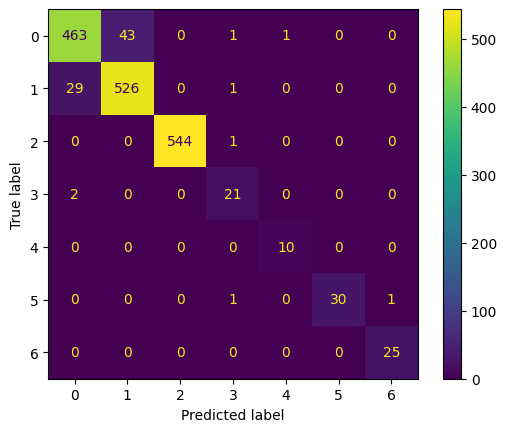

In [96]:
disp.plot()

In [97]:
print(classification_report(y_validation_inverse, classes_x))

              precision    recall  f1-score   support

           0       0.94      0.91      0.92       508
           1       0.92      0.95      0.94       556
           2       1.00      1.00      1.00       545
           3       0.84      0.91      0.87        23
           4       0.91      1.00      0.95        10
           5       1.00      0.94      0.97        32
           6       0.96      1.00      0.98        25

    accuracy                           0.95      1699
   macro avg       0.94      0.96      0.95      1699
weighted avg       0.95      0.95      0.95      1699



In [ ]:
print(segments_test)

In [ ]:
print(labels_test_categorical.shape)

In [ ]:
print(labels_test_categorical)

In [ ]:
loss_test, accuracy_test = best_model.evaluate(segments_test, labels_test_categorical)

In [ ]:
predictions_test = best_model.predict(segments_test)

In [ ]:
print(predictions_test)

In [ ]:
classes_x_test=np.argmax(predictions_test,axis=1)

In [ ]:
print(classes_x_test)

In [ ]:
labels_test_argmax = np.argmax(labels_test_categorical,axis=1)

In [ ]:
print(labels_test_argmax)

In [ ]:
from sklearn.metrics import confusion_matrix,ConfusionMatrixDisplay,classification_report
cm_test = confusion_matrix(labels_test_argmax, classes_x_test)

In [ ]:
disp_test = ConfusionMatrixDisplay(confusion_matrix=cm_test)
disp_test.plot()

In [ ]:
print(classification_report(labels_test_argmax, classes_x_test))

In [ ]:
best_model.save(WORKDIR+"/Model/best_models_saved_"+data_hora)